# Exploración del dataset de mi proyecto

Proyecto: **rebalanceo predictivo de cicloestaciones de Ecobici (CDMX)**. Archivo explorado: `../data/processed/flujo_estaciones_2026_08.csv`, el que deja [`calidad/preparar_datos.py`](../calidad/preparar_datos.py) a partir de los viajes de agosto de 2026: una fila por estación × día × franja de 15 minutos, para 100 estaciones (297,600 filas).

El modelo va a predecir `y_salidas_prox_30m`: cuántas bicicletas salen de la estación en los próximos 30 minutos, para anticipar qué estaciones se van a vaciar.

Este notebook es el registro de la exploración: el código, lo que mostró y lo que concluyo, en ese orden.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# El archivo limpio que deja calidad/preparar_datos.py: el flujo de Ecobici
# por estacion x dia x franja de 15 minutos, agosto de 2026, 100 estaciones.
# estacion_codigo se lee como texto por los codigos dobles como "271-272".
datos = pd.read_csv("../data/processed/flujo_estaciones_2026_08.csv", dtype={"estacion_codigo": str})

# Salidas de la estacion en los proximos 30 minutos (las 2 franjas siguientes).
OBJETIVO = "y_salidas_prox_30m"

## Paso 1: resumen

In [2]:
print("Filas y columnas:", datos.shape)
print(datos.dtypes)
print(datos.isna().sum())
datos.describe().round(2)

Filas y columnas: (297600, 18)
estacion_codigo                object
nombre                         object
latitud                       float64
longitud                      float64
capacidad                       int64
fecha                          object
hora                            int64
franja                          int64
dia_semana                      int64
es_fin_de_semana                 bool
es_hora_pico                     bool
salidas                         int64
llegadas                        int64
flujo_neto                      int64
salidas_lag_15m               float64
salidas_ultima_hora           float64
salidas_mismo_momento_ayer    float64
y_salidas_prox_30m            float64
dtype: object
estacion_codigo                  0
nombre                           0
latitud                          0
longitud                         0
capacidad                        0
fecha                            0
hora                             0
franja                    

,latitud,longitud,capacidad,hora,franja,dia_semana,salidas,llegadas,flujo_neto,salidas_lag_15m,salidas_ultima_hora,salidas_mismo_momento_ayer,y_salidas_prox_30m
count,297600.00,297600.00,297600.00,297600.00,297600.00,297600.00,297600.00,297600.00,297600.00,297500.00,297500.00,288000.00,297500.00
mean,19.40,-99.17,26.10,11.50,47.50,4.06,0.73,0.74,0.01,0.73,2.94,0.73,1.47
std,0.03,0.02,7.69,6.92,27.71,2.08,1.32,1.33,1.36,1.32,4.04,1.32,2.26
min,19.34,-99.21,11.00,0.00,0.00,1.00,0.00,0.00,-25.00,0.00,0.00,0.00,0.00
25%,19.38,-99.18,20.50,5.75,23.75,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,19.40,-99.17,27.00,11.50,47.50,4.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00
75%,19.43,-99.16,31.00,17.25,71.25,6.00,1.00,1.00,0.00,1.00,4.00,1.00,2.00
max,19.46,-99.13,59.00,23.00,95.00,7.00,25.00,24.00,22.00,25.00,56.00,25.00,35.00


## Paso 2: distribución de la variable objetivo

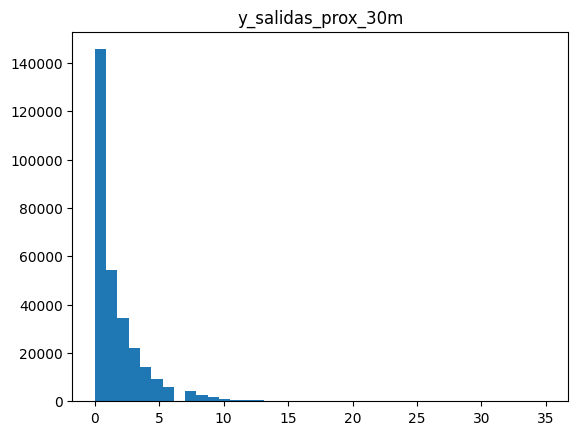

In [3]:
plt.figure()
# La ultima franja de cada estacion no tiene "proximos 30 minutos": su
# objetivo es NaN y no entra al histograma.
plt.hist(datos[OBJETIVO].dropna(), bins=40)
plt.title(OBJETIVO)
plt.show()

## Paso 3: atípicos de la variable objetivo con la regla del IQR

In [4]:
q1 = datos[OBJETIVO].quantile(0.25)
q3 = datos[OBJETIVO].quantile(0.75)
iqr = q3 - q1
fuera = datos[(datos[OBJETIVO] < q1 - 1.5 * iqr) | (datos[OBJETIVO] > q3 + 1.5 * iqr)]
print(f"Atipicos de {OBJETIVO} segun IQR: {len(fuera)}")
fuera.head(10)

Atipicos de y_salidas_prox_30m segun IQR: 18067


,estacion_codigo,nombre,latitud,longitud,capacidad,fecha,hora,franja,dia_semana,es_fin_de_semana,es_hora_pico,salidas,llegadas,flujo_neto,salidas_lag_15m,salidas_ultima_hora,salidas_mismo_momento_ayer,y_salidas_prox_30m
38,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,9,38,6,True,True,4,3,-1,1.0,7.0,NaN,6.0
39,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,9,39,6,True,True,1,3,2,4.0,8.0,NaN,8.0
40,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,10,40,6,True,False,5,3,-2,1.0,7.0,NaN,6.0
45,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,11,45,6,True,False,1,1,0,1.0,9.0,NaN,8.0
46,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,11,46,6,True,False,4,2,-2,1.0,7.0,NaN,7.0
47,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,11,47,6,True,False,4,1,-3,4.0,8.0,NaN,6.0
50,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,12,50,6,True,False,0,0,0,3.0,14.0,NaN,9.0
51,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,12,51,6,True,False,3,10,7,0.0,10.0,NaN,8.0
52,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,13,52,6,True,False,6,0,-6,3.0,9.0,NaN,7.0
53,007,CE-007 Río Elba - Río Lerma,19.42528,-99.175106,23,2026-08-01,13,53,6,True,False,2,1,-1,6.0,12.0,NaN,6.0


## Paso 4: la relación entre el objetivo y la variable que más esperas que influya

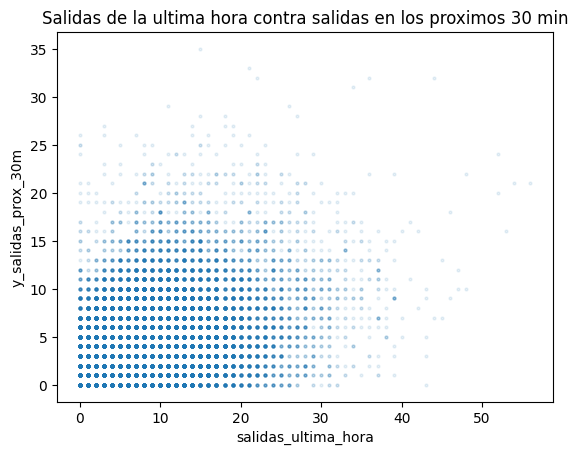

Correlacion: 0.6


In [5]:
# salidas_ultima_hora es la variable que mas espero que influya: una
# estacion con mucha demanda en la ultima hora deberia seguir con demanda en
# la proxima media hora.
plt.figure()
plt.scatter(datos["salidas_ultima_hora"], datos[OBJETIVO], s=4, alpha=0.1)
plt.xlabel("salidas_ultima_hora")
plt.ylabel(OBJETIVO)
plt.title("Salidas de la ultima hora contra salidas en los proximos 30 min")
plt.show()
print("Correlacion:", round(datos[["salidas_ultima_hora", OBJETIVO]].corr().iloc[0, 1], 3))

## Paso 5: tres hallazgos que afectarían el modelado

Para cada hallazgo: una celda de código con la consulta o el gráfico que lo confirma (un filtro, un `groupby`, una correlación), y debajo una celda de texto con qué encontraste, el número que lo confirma y qué cambia en el modelo por su causa (una fila que quitas, una columna que no puedes usar, una variable que hay que transformar).

### Hallazgo 1

In [6]:
# Hallazgo 1: cuantas franjas no tienen ninguna salida en los proximos 30 minutos.
print("Proporcion de franjas con objetivo 0:", round((datos[OBJETIVO] == 0).mean(), 3))
print(datos[OBJETIVO].value_counts(normalize=True).sort_index().head(6).round(3))

Proporcion de franjas con objetivo 0: 0.489
y_salidas_prox_30m
0.0    0.489
1.0    0.183
2.0    0.115
3.0    0.074
4.0    0.047
5.0    0.031
Name: proportion, dtype: float64


**Casi la mitad de las franjas no tiene ninguna salida.** El 48.9% de las franjas tiene el objetivo en 0, y el 78.7% tiene 2 salidas o menos (0: 48.9%, 1: 18.3%, 2: 11.5%). La cola es larga: el IQR marca 18,067 franjas como atípicas, y no son errores sino las estaciones y horas de mucha demanda, que son justo las que más importa predecir.

**Qué cambia en el modelo:** no se quitan los atípicos. El error se mide con MAE, que no deja que unas pocas franjas muy altas dominen la métrica como lo haría el RMSE, y la línea base tiene que ser una regla que no aprende (persistencia de las últimas franjas), porque predecir siempre la media o la mediana ya acierta casi la mitad de las veces.

### Hallazgo 2

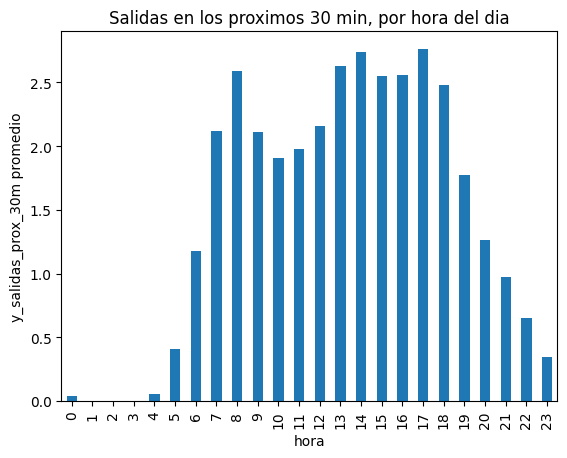

hora
0     0.04
1     0.00
2     0.00
3     0.00
4     0.05
5     0.41
6     1.18
7     2.12
8     2.59
9     2.11
10    1.90
11    1.98
12    2.15
13    2.63
14    2.74
15    2.55
16    2.56
17    2.76
18    2.48
19    1.77
20    1.26
21    0.97
22    0.65
23    0.35
es_fin_de_semana
False    1.65
True     1.09
Name: y_salidas_prox_30m, dtype: float64


In [7]:
# Hallazgo 2: la demanda depende de la hora y del tipo de dia.
por_hora = datos.groupby("hora")[OBJETIVO].mean()
plt.figure()
por_hora.plot(kind="bar")
plt.ylabel(f"{OBJETIVO} promedio")
plt.title("Salidas en los proximos 30 min, por hora del dia")
plt.show()
print(por_hora.round(2).to_string())
print(datos.groupby("es_fin_de_semana")[OBJETIVO].mean().round(2))

**La demanda depende de la hora y del tipo de día.** Entre la 1 y las 3 de la mañana el objetivo promedio es 0.00 (el sistema no opera), sube desde las 6 (1.18) y tiene dos picos: de 7 a 9 (hasta 2.59 a las 8) y de 13 a 18 (hasta 2.76 a las 17). Entre semana el promedio es 1.65 y en fin de semana 1.09, un tercio menos.

**Qué cambia en el modelo:** la hora y el tipo de día tienen que estar entre las features: entran `hora`, `dia_semana` y `es_fin_de_semana`, y como la relación con la hora no es una recta (sube, baja y vuelve a subir), de este hallazgo sale la feature `periodo_demanda` (madrugada, pico de la mañana, pico de la tarde y resto) en [`features_proyecto.ipynb`](features_proyecto.ipynb). Además, como el patrón se repite cada día, la división tiene que ser por fecha y no al azar, para no mezclar franjas vecinas entre entrenamiento y prueba.

### Hallazgo 3

In [8]:
# Hallazgo 3: la historia reciente de la estacion explica el objetivo mejor
# que sus atributos fijos.
columnas = ["salidas", "salidas_lag_15m", "salidas_ultima_hora", "salidas_mismo_momento_ayer", "capacidad"]
datos[columnas].corrwith(datos[OBJETIVO]).round(3)

salidas                       0.526
salidas_lag_15m               0.493
salidas_ultima_hora           0.600
salidas_mismo_momento_ayer    0.429
capacidad                     0.125
dtype: float64

**La historia reciente de la estación explica el objetivo mucho mejor que sus atributos fijos.** La correlación con el objetivo es 0.600 para `salidas_ultima_hora`, 0.526 para las salidas de la franja actual, 0.493 para la franja anterior y 0.429 para el mismo momento de ayer, contra solo 0.125 para la `capacidad`.

**Qué cambia en el modelo:** los rezagos son las features centrales, y por eso no hace falta codificar las 100 estaciones con one-hot: la historia reciente ya describe a cada estación. Los rezagos tienen faltantes al inicio de cada serie (100 en los de 15 minutos y una hora, 9,600 en el de ayer, todo el primer día), que se imputan dentro del pipeline con la mediana de entrenamiento. Y como el objetivo es el futuro de esa misma serie, cada rezago se calcula solo con franjas anteriores: nunca con la que se quiere predecir.